# ML1_Pipeline + Model

Ce notebook est en plusieurs étapes :
1. Comment charger et préparer les données
2. Comment utiliser correctement train_test_split
3. Comment créer des pipelines de prétraitement
4. Comment implémenter et évaluer un modèle de régression

## Objectif
Prédire l'année de plantation des arbres en utilisant les bonnes pratiques de Machine Learning.

## 1. Import des bibliothèques nécessaires et chargement des données.

Nous utilisons plusieurs bibliothèques essentielles :
- pandas et numpy : pour la manipulation des données
- sklearn : pour le Machine Learning
- matplotlib : pour la visualisation

In [33]:
# Les libraries nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

Nous chargeons les données depuis le fichier pickle qui contient notre dataset nettoyé.

In [2]:
# Chargement des données depuis le fichier pickle
df = pd.read_pickle('/home/sami.chircop@Digital-Grenoble.local/Documents/ML1/data/trees.pkl')

df['Latitude'] = df['Latitude'].map(lambda x:float(x))
df['Longitude'] = df['Longitude'].map(lambda x:float(x))
df['adr_secteur'] = df['adr_secteur'].map(lambda x:str(x))

## 2. Préparation des données pour le ML et séparation train_test

Première étape importante : supprimer les nan de la target puis séparer nos variables explicatives (features) de notre variable cible (target).

Deuxième étape : separation Train-Test

In [3]:
annee = df.pop('anneedeplantation')

In [4]:
# Suppression des lignes sans année de plantation
# On peut utiliser la méthode *dropna()* pour supprimer les lignes où la anneedeplantation est NaN
#DEJA FAIT

# Séperation train/test
# On peut utiliser la méthode *train_test_split()* de scikit-learn pour séparer les données en ensembles d'entraînement et de test
X_train, X_test, y_train, y_test = train_test_split(df, annee, random_state=28)

## [Optionnel] Comment on peut remplir les valeurs manquantes sans utiliser le pipeline?

In [5]:
# Remplir les valeurs manquantes avec la valeur la plus fréquente pour chaque colonne concernée

## [Optionnel] Création de nouvelles variables (Feature Engineering)

In [6]:
# Code

## 3. Création des pipelines de prétraitement

Les pipelines sont essentiels pour :
1. Automatiser les transformations
2. Éviter le data leakage
3. Assurer la cohérence entre train et test

### 3.1 Préparation des données & modèle de base

Nous préparons les données en utilisant un pipeline `scikit-learn` :
- **OneHotEncoder** pour les variables catégorielles
- **StandardScaler** pour les variables numériques
- **LinearRegression** comme modèle de base

In [ ]:
# Quelles sont les variables catégorielles et variables numériques ?
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.compose import make_column_selector as selector

# OneHotEncoder ?
#Toute sauf latitude et longitude
cat_var = df.select_dtypes(include=str).columns.tolist()

# StandardScaler ?
#latitude et longitude
num_var = df.select_dtypes(exclude=str).columns.tolist()

pipeline = ColumnTransformer([
    ("Numerical standardization", StandardScaler(), num_var),
     ("Categorical standardization", OneHotEncoder(handle_unknown='ignore'), cat_var)
])
#ridge needs sparce = False
X_prepared = pipeline.fit_transform(X_train)
X_test_prepared = pipeline.transform(X_test)


In [ ]:
# [OPTIONNEL] Vérification rapide des valeurs manquantes
# Doit etre 0 pour toutes les colonnes pour le train et le test
X_train.isna().sum(axis=0)
X_test.isna().sum(axis=0)

sous_categorie             0
sous_categorie_desc        0
code_parent                0
code_parent_desc           0
adr_secteur                0
genre_bota                31
espece                   912
stadededeveloppement    1873
collectivite              70
hauteurarbre            4344
portarbre               8403
structure                112
typenature              8403
Latitude                   0
Longitude                  0
dtype: int64

## 4. Evaluation avec LinearRegression et plusieurs métriques :
- **MAE** (Mean Absolute Error)
- D'autres?

Ce modèle simple nous servira de point de comparaison pour des modèles plus avancés (comme les arbres de décision ou les forêts aléatoires).

In [36]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_prepared, y_train)

# predict y values for testing data set
y_pred_test = cross_val_predict(lin_reg, X_test_prepared, y_test, cv = 5)

#Cross-validation
cv_scores = cross_val_score(lin_reg, X_prepared, y_train, cv = 5, scoring='neg_mean_squared_error')
print('mean CV MSE:',np.mean(-cv_scores))
print('std CV MSE:',np.std(-cv_scores))

# evaluate MAE
mae_test = mean_absolute_error(y_test, y_pred_test)
print('test MAE: {0}'.format(mae_test))

# evaluate MSE
mse_test = mean_squared_error(y_test, y_pred_test)
print('test MSE: {0}'.format(mse_test))

# evaluate MSE
rmse_test = root_mean_squared_error(y_test, y_pred_test)
print('test MSE: {0}'.format(rmse_test))

mean CV MSE: 122.08635672802248
std CV MSE: 2.4147199399311834
test MAE: 8.724931889045783
test MSE: 136.10106558314686
test MSE: 11.666236136095774


## 5. Visualisation des prédictions

Visualisons la relation entre les valeurs réelles et prédites :

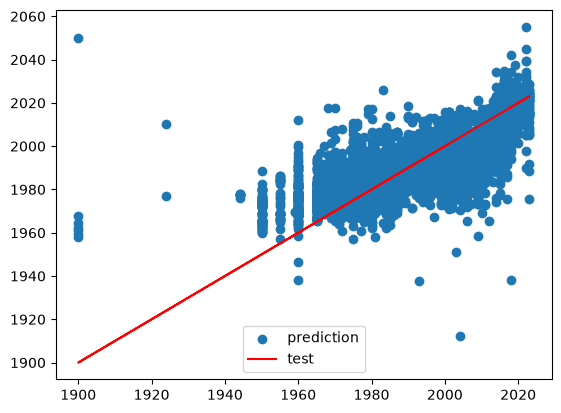

In [48]:
# Code
plt.scatter(y_test, y_pred_test)
plt.plot(y_test,y_test, 'r')
plt.legend(['prediction','test'])

## Conclusion